# DPS XGBoost Regression Model
**M.Tech Research — Impact of AI on Developer Productivity**

This notebook:
1. Loads the cleaned feature dataset + DPS labels (computed by `dps_pipeline_v2.py`)
2. Engineers the 3 AIS features (same formula as the pipeline)
3. Preprocesses features (log1p → 1–99 clip → RobustScaler)
4. Trains an **XGBoost Regressor** to predict the DPS score
5. Evaluates with RMSE, MAE, R² and cross-validation
6. Produces Feature Importance and SHAP explainability plots


## 0 · Imports & Setup

In [24]:
import warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import xgboost as xgb

BASE = os.path.dirname(os.path.abspath("__file__"))
SEED = 42
np.random.seed(SEED)

print(f"XGBoost version : {xgb.__version__}")


XGBoost version : 3.1.2


## 1 · Load & Merge Data

In [25]:
# Feature source (45 cols — raw cleaned data)
df_feat = pd.read_csv(os.path.join(BASE, "cleaned_features_v2.csv"))

# Label source (DPS computed by entropy-weighted composite index pipeline)
df_dps  = pd.read_csv(os.path.join(BASE, "dps_final.csv"))[["pr_id", "DPS",
          "Productivity_Class",
          "ai_contribution_intensity", "ai_review_friction", "ai_rework_ratio"]]

# Merge on pr_id
df = df_feat.merge(df_dps, on="pr_id", how="inner")
print(f"Merged shape : {df.shape}")
print(f"Nulls        : {df.isnull().sum().sum()}")
print(f"DPS — mean={df.DPS.mean():.4f}  std={df.DPS.std():.4f}  "
      f"min={df.DPS.min():.4f}  max={df.DPS.max():.4f}")
df.head(3)


Merged shape : (22258, 50)
Nulls        : 0
DPS — mean=0.2865  std=0.0812  min=0.0034  max=0.7993


,pr_id,pr_number,repo_url,pr_completion_time_hours,commit_count,files_changed_count,lines_added,lines_deleted,total_code_changes,merge_success,...,lang_Kotlin,lang_Other,lang_Python,lang_Rust,lang_TypeScript,DPS,Productivity_Class,ai_contribution_intensity,ai_review_friction,ai_rework_ratio
0,3264933329,2911,https://api.github.com/repos/milvus-io/pymilvus,0.014593,0.693147,1.386294,5.978886,1.098612,5.983936,0,...,0,0,1,0,0,0.356958,Low,5.293305,0.000000,0.000000
1,3265118634,2,https://api.github.com/repos/classmethod/tsumiki,2.904609,0.693147,2.484907,3.663562,3.663562,4.343805,1,...,0,0,0,0,1,0.120364,Low,3.663561,0.000000,0.000000
2,3265640341,30,https://api.github.com/repos/steipete/Peekaboo,0.096037,1.945910,1.791759,5.700444,4.700480,6.011267,1,...,0,1,0,0,0,0.298674,Low,2.369355,2.564942,1.945903


## 2 · Feature Engineering
Re-use the 3 AIS engineered features already computed by the pipeline (loaded from `dps_final.csv`).
The formulas are:
- `ai_contribution_intensity = (ai_contribution_ratio × total_code_changes) / (commit_count + 1)`
- `ai_review_friction        = pr_review_count / (ai_contribution_ratio + ε)`
- `ai_rework_ratio           = rework_count    / (ai_contribution_ratio + ε)`


In [26]:
# AIS features are already merged from dps_final.csv — confirm
for col in ["ai_contribution_intensity", "ai_review_friction", "ai_rework_ratio"]:
    print(f"  {col}: min={df[col].min():.4f}  max={df[col].max():.4f}  "
          f"mean={df[col].mean():.4f}  nulls={df[col].isnull().sum()}")


  ai_contribution_intensity: min=0.4055  max=8.1708  mean=3.4606  nulls=0
  ai_review_friction: min=0.0000  max=3.0910  mean=0.1662  nulls=0
  ai_rework_ratio: min=0.0000  max=3.2189  mean=0.0969  nulls=0


## 3 · Feature Matrix Construction
**14 DPS pipeline features** (same set the composite index uses) + language dummies.  
This lets XGBoost learn to predict DPS from the raw/cleaned inputs — useful for inference
on new PRs without running the full entropy-weighting pipeline.


In [27]:
# Core 14 pipeline features
PIPELINE_FEATS = [
    # TES
    "pr_completion_time_hours", "commit_count", "issue_resolution_count",
    # CQS
    "approval_status", "bug_fix_indicator",
    # CLS
    "high_context_changes", "timeline_interruptions", "pr_lifecycle_duration_hours",
    # AIS (engineered)
    "ai_contribution_intensity", "ai_review_friction", "ai_rework_ratio",
    # RCS
    "repo_stars", "contributor_count", "repo_size_kb",
]

# Additional raw behavioral features (extra signal for XGBoost)
EXTRA_FEATS = [
    "files_changed_count", "lines_added", "lines_deleted", "total_code_changes",
    "merge_success", "review_turnaround_time_hours", "pr_review_count",
    "rework_count", "bug_fix_commit_count", "large_pr_flag",
    "comment_density", "ai_contribution_ratio", "ai_generated_commit_count",
    "has_review", "is_claude_code",
]

# Language dummies
LANG_FEATS = [c for c in df.columns if c.startswith("lang_")]

ALL_FEATS = PIPELINE_FEATS + EXTRA_FEATS + LANG_FEATS

# Keep only columns that exist and have non-zero variance
ALL_FEATS = [f for f in ALL_FEATS if f in df.columns and df[f].std() > 0]
print(f"Total features selected : {len(ALL_FEATS)}")
print(ALL_FEATS)


Total features selected : 38
['pr_completion_time_hours', 'commit_count', 'issue_resolution_count', 'approval_status', 'bug_fix_indicator', 'high_context_changes', 'timeline_interruptions', 'pr_lifecycle_duration_hours', 'ai_contribution_intensity', 'ai_review_friction', 'ai_rework_ratio', 'repo_stars', 'contributor_count', 'repo_size_kb', 'files_changed_count', 'lines_added', 'lines_deleted', 'total_code_changes', 'merge_success', 'review_turnaround_time_hours', 'pr_review_count', 'rework_count', 'bug_fix_commit_count', 'large_pr_flag', 'ai_contribution_ratio', 'has_review', 'is_claude_code', 'lang_C#', 'lang_Dart', 'lang_Go', 'lang_HTML', 'lang_Java', 'lang_JavaScript', 'lang_Kotlin', 'lang_Other', 'lang_Python', 'lang_Rust', 'lang_TypeScript']


## 4 · Preprocessing
Pipeline:  `log1p` → global 1–99 percentile clip → `RobustScaler`  
*(mirrors the preprocessing in `dps_pipeline_v2.py`)*


In [28]:
X = df[ALL_FEATS].copy().fillna(0)
y = df["DPS"].values

# Step 1: log1p on strictly positive-skewed continuous features
SKEWED = [
    "pr_completion_time_hours", "commit_count", "issue_resolution_count",
    "files_changed_count", "lines_added", "lines_deleted", "total_code_changes",
    "review_turnaround_time_hours", "pr_review_count", "rework_count",
    "bug_fix_commit_count", "comment_density", "ai_contribution_ratio",
    "ai_generated_commit_count", "repo_stars", "contributor_count", "repo_size_kb",
    "ai_contribution_intensity", "ai_review_friction", "ai_rework_ratio",
    "pr_lifecycle_duration_hours",
]
SKEWED = [f for f in SKEWED if f in X.columns]
X[SKEWED] = np.log1p(X[SKEWED].clip(lower=0))

# Step 2: Global 1–99 percentile clip
for col in X.columns:
    lo, hi = X[col].quantile(0.01), X[col].quantile(0.99)
    if hi > lo:
        X[col] = X[col].clip(lo, hi)

# Step 3: RobustScaler
scaler = RobustScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print(f"X shape : {X_scaled.shape}")
print(f"y — mean={y.mean():.4f}  std={y.std():.4f}  min={y.min():.4f}  max={y.max():.4f}")


X shape : (22258, 38)
y — mean=0.2865  std=0.0812  min=0.0034  max=0.7993


## 5 · Train / Test Split (80 / 20, stratified on Productivity_Class)

In [29]:
strat = df["Productivity_Class"].values  # High / Moderate / Low

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=SEED, stratify=strat
)
print(f"Train : {X_train.shape}  |  Test : {X_test.shape}")

# Class distribution check
train_cls = df.loc[X_train.index, "Productivity_Class"].value_counts(normalize=True)
test_cls  = df.loc[X_test.index,  "Productivity_Class"].value_counts(normalize=True)
pd.DataFrame({"Train %": train_cls*100, "Test %": test_cls*100}).round(2)


Train : (17806, 38)  |  Test : (4452, 38)


,Train %,Test %
Productivity_Class,,
Low,91.38,91.37
Moderate,8.37,8.38
High,0.25,0.25


## 6 · Baseline XGBoost Regressor

In [30]:
xgb_base = xgb.XGBRegressor(
    n_estimators   = 500,
    learning_rate  = 0.05,
    max_depth      = 6,
    subsample      = 0.8,
    colsample_bytree = 0.8,
    reg_alpha      = 0.1,
    reg_lambda     = 1.0,
    random_state   = SEED,
    n_jobs         = -1,
    verbosity      = 0,
)

xgb_base.fit(
    X_train, y_train,
    eval_set        = [(X_test, y_test)],
    verbose         = 50,
)

y_pred_base = xgb_base.predict(X_test)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
mae_base  = mean_absolute_error(y_test, y_pred_base)
r2_base   = r2_score(y_test, y_pred_base)
print(f"\nBaseline  RMSE={rmse_base:.5f}  MAE={mae_base:.5f}  R²={r2_base:.5f}")


[0]	validation_0-rmse:0.07862
[50]	validation_0-rmse:0.01655
[100]	validation_0-rmse:0.00771
[150]	validation_0-rmse:0.00594
[200]	validation_0-rmse:0.00531
[250]	validation_0-rmse:0.00500
[300]	validation_0-rmse:0.00478
[350]	validation_0-rmse:0.00463
[400]	validation_0-rmse:0.00451
[450]	validation_0-rmse:0.00443
[499]	validation_0-rmse:0.00437

Baseline  RMSE=0.00437  MAE=0.00212  R²=0.99712


## 7 · Hyperparameter Tuning (RandomizedSearchCV, 5-Fold CV)

In [31]:
param_dist = {
    "n_estimators"     : [300, 500, 700],
    "max_depth"        : [4, 6, 8],
    "learning_rate"    : [0.01, 0.03, 0.05, 0.1],
    "subsample"        : [0.7, 0.8, 0.9],
    "colsample_bytree" : [0.7, 0.8, 0.9],
    "reg_alpha"        : [0, 0.1, 0.5, 1.0],
    "reg_lambda"       : [0.5, 1.0, 2.0],
    "min_child_weight" : [1, 3, 5],
}

xgb_cv = xgb.XGBRegressor(random_state=SEED, n_jobs=-1, verbosity=0)

rs = RandomizedSearchCV(
    xgb_cv,
    param_distributions = param_dist,
    n_iter              = 40,
    scoring             = "neg_root_mean_squared_error",
    cv                  = KFold(n_splits=5, shuffle=True, random_state=SEED),
    verbose             = 1,
    random_state        = SEED,
    n_jobs              = -1,
)
rs.fit(X_train, y_train)

print("\nBest params:", rs.best_params_)
print(f"Best CV RMSE : {-rs.best_score_:.5f}")


Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best params: {'subsample': 0.8, 'reg_lambda': 0.5, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV RMSE : 0.00396


## 8 · Final Model — Fit Best Params with Early Stopping

In [32]:
best_p = rs.best_params_

xgb_final = xgb.XGBRegressor(
    **best_p,
    early_stopping_rounds = 30,
    random_state = SEED,
    n_jobs       = -1,
    verbosity    = 0,
)
xgb_final.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    verbose  = 50,
)

y_pred = xgb_final.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print(f"\n{'Metric':<10} {'Baseline':>12} {'Tuned':>12}")
print(f"{'RMSE':<10} {rmse_base:>12.5f} {rmse:>12.5f}")
print(f"{'MAE':<10} {mae_base:>12.5f} {mae:>12.5f}")
print(f"{'R²':<10} {r2_base:>12.5f} {r2:>12.5f}")


[0]	validation_0-rmse:0.07683
[50]	validation_0-rmse:0.01072
[100]	validation_0-rmse:0.00586
[150]	validation_0-rmse:0.00485
[200]	validation_0-rmse:0.00441
[250]	validation_0-rmse:0.00412
[300]	validation_0-rmse:0.00393
[350]	validation_0-rmse:0.00380
[400]	validation_0-rmse:0.00369
[450]	validation_0-rmse:0.00362
[499]	validation_0-rmse:0.00356

Metric         Baseline        Tuned
RMSE            0.00437      0.00356
MAE             0.00212      0.00190
R²              0.99712      0.99809


## 9 · 5-Fold Cross-Validation on Full Dataset

In [33]:
cv_xgb = xgb.XGBRegressor(**best_p, random_state=SEED, n_jobs=-1, verbosity=0)

cv_rmse = cross_val_score(cv_xgb, X_scaled, y,
                          cv=KFold(5, shuffle=True, random_state=SEED),
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
cv_r2   = cross_val_score(cv_xgb, X_scaled, y,
                          cv=KFold(5, shuffle=True, random_state=SEED),
                          scoring="r2", n_jobs=-1)

print(f"CV RMSE : {-cv_rmse.mean():.5f} ± {cv_rmse.std():.5f}")
print(f"CV R²   : {cv_r2.mean():.5f} ± {cv_r2.std():.5f}")


CV RMSE : 0.00367 ± 0.00006
CV R²   : 0.99796 ± 0.00013


## 10 · Evaluation Plots

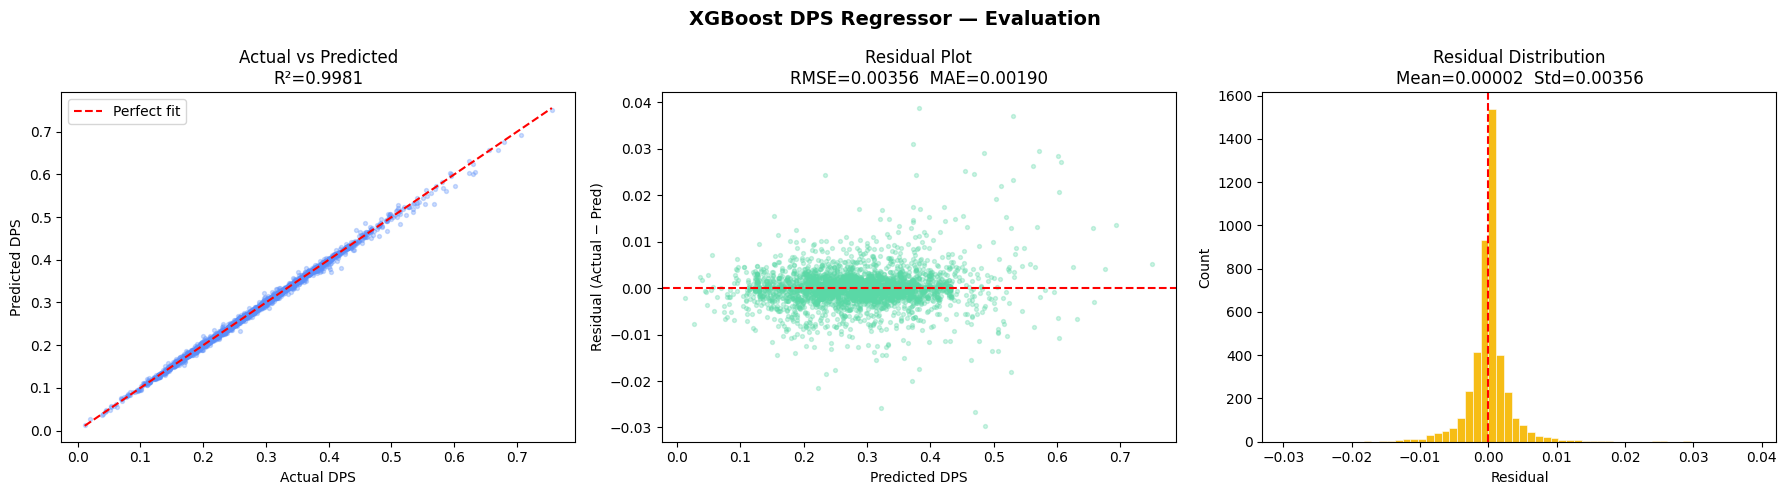

Saved: xgb_evaluation.png


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("XGBoost DPS Regressor — Evaluation", fontsize=14, fontweight="bold")

# Panel 1: Actual vs Predicted
ax = axes[0]
ax.scatter(y_test, y_pred, alpha=0.3, s=8, color="#5B8FF9")
mn, mx = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
ax.plot([mn, mx], [mn, mx], "r--", lw=1.5, label="Perfect fit")
ax.set_xlabel("Actual DPS"); ax.set_ylabel("Predicted DPS")
ax.set_title(f"Actual vs Predicted\nR²={r2:.4f}")
ax.legend()

# Panel 2: Residuals
residuals = y_test - y_pred
ax = axes[1]
ax.scatter(y_pred, residuals, alpha=0.3, s=8, color="#5AD8A6")
ax.axhline(0, color="red", lw=1.5, ls="--")
ax.set_xlabel("Predicted DPS"); ax.set_ylabel("Residual (Actual − Pred)")
ax.set_title(f"Residual Plot\nRMSE={rmse:.5f}  MAE={mae:.5f}")

# Panel 3: Residual distribution
ax = axes[2]
ax.hist(residuals, bins=60, color="#F6BD16", edgecolor="white", lw=0.4)
ax.axvline(0, color="red", lw=1.5, ls="--")
ax.set_xlabel("Residual"); ax.set_ylabel("Count")
ax.set_title(f"Residual Distribution\nMean={residuals.mean():.5f}  Std={residuals.std():.5f}")

plt.tight_layout()
plt.savefig("xgb_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: xgb_evaluation.png")


## 11 · Feature Importance (Built-in Gain)

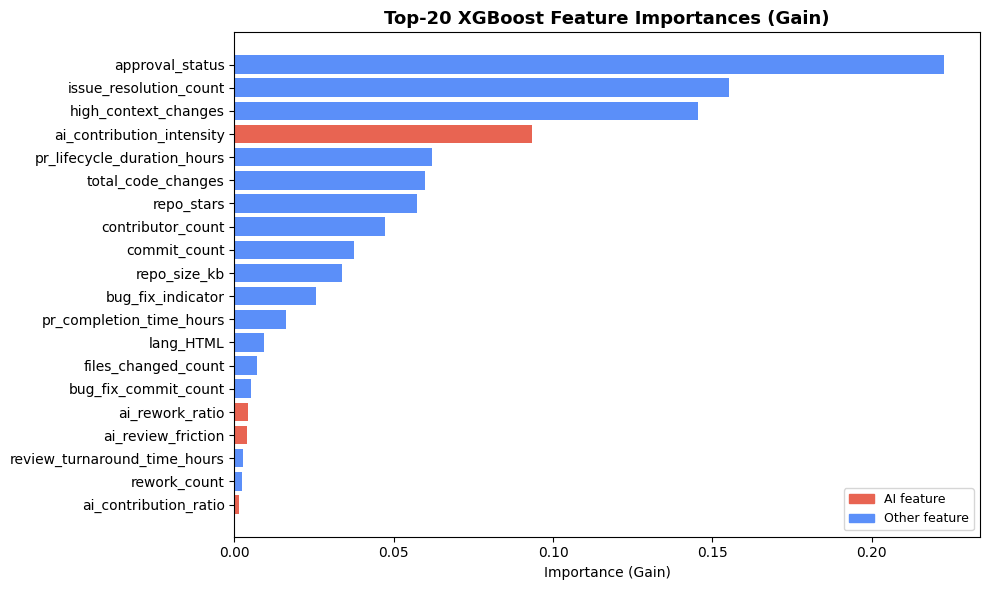

                     Feature  Importance
             approval_status    0.222821
      issue_resolution_count    0.155046
        high_context_changes    0.145496
   ai_contribution_intensity    0.093421
 pr_lifecycle_duration_hours    0.062048
          total_code_changes    0.059909
                  repo_stars    0.057384
           contributor_count    0.047110
                commit_count    0.037513
                repo_size_kb    0.033771
           bug_fix_indicator    0.025611
    pr_completion_time_hours    0.016169
                   lang_HTML    0.009239
         files_changed_count    0.007212
        bug_fix_commit_count    0.005073
             ai_rework_ratio    0.004402
          ai_review_friction    0.003938
review_turnaround_time_hours    0.002660
                rework_count    0.002493
       ai_contribution_ratio    0.001480


In [35]:
imp = pd.DataFrame({
    "Feature"   : X_train.columns,
    "Importance": xgb_final.feature_importances_,
}).sort_values("Importance", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#E86452" if "ai_" in f else "#5B8FF9" for f in imp["Feature"]]
ax.barh(imp["Feature"][::-1], imp["Importance"][::-1], color=colors[::-1])
ax.set_title("Top-20 XGBoost Feature Importances (Gain)", fontsize=13, fontweight="bold")
ax.set_xlabel("Importance (Gain)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#E86452", label="AI feature"),
                   Patch(color="#5B8FF9", label="Other feature")], fontsize=9)
plt.tight_layout()
plt.savefig("xgb_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(imp.to_string(index=False))


## 13 · Save Model & Predictions

In [36]:
import json

# Save model
xgb_final.save_model("dps_xgboost_model.json")
print("Model saved -> dps_xgboost_model.json")

# Save predictions alongside actual DPS and pr_id
pred_df = pd.DataFrame({
    "pr_id"       : df.loc[X_test.index, "pr_id"].values,
    "ai_tool_type": df.loc[X_test.index, "ai_tool_type"].values,
    "DPS_actual"  : y_test,
    "DPS_predicted": y_pred,
    "residual"    : y_test - y_pred,
})
pred_df.to_csv("dps_xgb_predictions.csv", index=False)
print("Predictions saved -> dps_xgb_predictions.csv")
print(pred_df.describe().round(5))


Model saved -> dps_xgboost_model.json
Predictions saved -> dps_xgb_predictions.csv
              pr_id  DPS_actual  DPS_predicted    residual
count  4.452000e+03  4452.00000     4452.00000  4452.00000
mean   3.174362e+09     0.28553        0.28551     0.00002
std    6.137158e+07     0.08129        0.08084     0.00356
min    2.888185e+09     0.01105        0.01324    -0.02964
25%    3.126426e+09     0.24155        0.24152    -0.00090
50%    3.173029e+09     0.26838        0.26827     0.00000
75%    3.226160e+09     0.33907        0.33932     0.00083
max    3.278146e+09     0.75556        0.75046     0.03873


In [37]:
# Final summary
print("=" * 55)
print("   XGBoost DPS Regressor — Final Summary")
print("=" * 55)
print(f"  Dataset          : {len(df):,} PRs × {len(ALL_FEATS)} features")
print(f"  Train / Test     : {len(X_train):,} / {len(X_test):,}")
print(f"  Best params      : {best_p}")
print(f"  Test RMSE        : {rmse:.5f}")
print(f"  Test MAE         : {mae:.5f}")
print(f"  Test R²          : {r2:.5f}")
print(f"  CV RMSE (5-fold) : {-cv_rmse.mean():.5f} ± {cv_rmse.std():.5f}")
print(f"  CV R²  (5-fold)  : {cv_r2.mean():.5f} ± {cv_r2.std():.5f}")
print("=" * 55)


   XGBoost DPS Regressor — Final Summary
  Dataset          : 22,258 PRs × 38 features
  Train / Test     : 17,806 / 4,452
  Best params      : {'subsample': 0.8, 'reg_lambda': 0.5, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
  Test RMSE        : 0.00356
  Test MAE         : 0.00190
  Test R²          : 0.99809
  CV RMSE (5-fold) : 0.00367 ± 0.00006
  CV R²  (5-fold)  : 0.99796 ± 0.00013
